# 🧭 SARSA no labirinto: aprender com o caminho que você faz de verdade

Este notebook acompanha os **slides 107 a 110** da aula.

**A analogia (slide 108):** o motorista que aprende com o caminho que **de fato fez**, com desvios e erros, e não com o caminho perfeito que poderia ter feito.

### O nome: as cinco peças de cada atualização

| S | A | R | S′ | A′ |
|---|---|---|---|---|
| estado atual | ação escolhida | recompensa recebida | próximo estado | **próxima ação**, a que o agente vai tomar de fato |

### A regra do SARSA

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[\,r + \gamma \cdot Q(s',a') - Q(s,a)\,\big]$$

A **única** diferença para o Q-Learning está no alvo:

| | Alvo | Tipo |
|---|---|---|
| **Q-Learning** | $r + \gamma \cdot \max_{a'} Q(s',a')$, supõe que dali em diante vai jogar perfeito | off-policy |
| **SARSA** | $r + \gamma \cdot Q(s',a')$, usa a ação que o ε-greedy **realmente sorteou** | **on-policy** |

### Roteiro (≈ 35 min)

| Seção | O que você faz | Slides | Tempo |
|---|---|---|---|
| 1 | SARSA na conta: a mesma casa, outro alvo | 109 | 5 min |
| 2 | Aquecimento: um labirinto pequeno, número por número | 108 | 7 min |
| 3 | 🎯 **Mão na massa 1** — assista ao agente no labirinto 51×51 | 110 | 7 min |
| 4 | 🎯 **Mão na massa 2** — leia a política | 110 | 5 min |
| 5 | A pergunta da turma: como aprender o labirinto **inteiro**? | 110 | 5 min |
| 6 | 🎯 **Mão na massa 3** — mexa nos hiperparâmetros | 110 e 106 | 6 min |

> **Como usar:** rode as células em ordem (Shift + Enter). Sempre que aparecer **🤔 Palpite**, a dupla escreve a aposta **antes** de rodar. Depois, confira no **🔎 O que observar**. Onde aparecer 👈, troque o valor e rode de novo.

### 🎯 Aquecimento: quem é quem?

O agente estava na casa (1, 1), foi para a **Direita**, levou **−1**, chegou na casa (1, 2) e, para o próximo passo, o ε-greedy sorteou **Baixo**. Quem é S, A, R, S′ e A′?

<details>
<summary><b>Ver resposta</b></summary>

S = (1, 1) · A = Direita · R = −1 · S′ = (1, 2) · A′ = Baixo. O SARSA só consegue atualizar Q(S, A) **depois** de sortear A′.
</details>

In [1]:
import time
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

br = lambda x, d=2: f'{x:.{d}f}'.replace('.', ',')   # número no formato brasileiro

---
## 1. SARSA na conta: a mesma casa, outro alvo (slide 109)

A mesma cena da cobrinha (slides 104 e 109): ela sai do **início** para **cima**, rumo ao **Vazio 2**, cujo melhor Q é **10** (subir até as 5 maçãs). Ir para a **direita** a partir do Vazio 2 cai na armadilha: Q = **−10**.

- Antes: Q(Vazio 1, Cima) = **−1** · recompensa = **−1** · α = 0,5 · γ = 0,9
- **Mas o ε-greedy sorteou explorar:** o próximo passo será **Direita**.

> 🤔 **Palpite:** depois da atualização, o novo Q(Vazio 1, Cima) fica maior no Q-Learning ou no SARSA? Algum dos dois fica negativo?

In [2]:
# ======================================================================
# 📚 NA AULA · SARSA × Q-LEARNING: o mesmo passo, dois alvos diferentes
# ======================================================================
alpha, gamma = 0.5, 0.9
Q_antes = -1.0                                  # Q(Vazio 1, Cima)
r = -1.0                                        # recompensa da casa vazia
Q_vazio2 = {'Cima': 10.0, 'Direita': -10.0}     # o que já se sabe do Vazio 2


def mostrar(nome, usado, alvo):
    novo = Q_antes + alpha * (alvo - Q_antes)
    print(f'{nome:11s} usa {usado:28s} alvo = −1 + 0,9 × ({br(alvo_futuro[nome], 0)}) = {br(alvo, 1):>5s}'
          f'   →   novo Q = −1 + 0,5 × ({br(alvo, 1)} − (−1)) = {br(novo, 2)}')


a_prox = 'Direita'                              # 👈 o que o ε-greedy sorteou (troque para 'Cima')
alvo_futuro = {'Q-Learning': max(Q_vazio2.values()), 'SARSA': Q_vazio2[a_prox]}
mostrar('Q-Learning', 'max Q(Vazio 2, ·) = 10', r + gamma * alvo_futuro['Q-Learning'])
mostrar('SARSA', f"Q(Vazio 2, {a_prox}) = {br(Q_vazio2[a_prox], 0)}", r + gamma * alvo_futuro['SARSA'])

Q-Learning  usa max Q(Vazio 2, ·) = 10       alvo = −1 + 0,9 × (10) =   8,0   →   novo Q = −1 + 0,5 × (8,0 − (−1)) = 3,50
SARSA       usa Q(Vazio 2, Direita) = -10    alvo = −1 + 0,9 × (-10) = -10,0   →   novo Q = −1 + 0,5 × (-10,0 − (−1)) = -5,50


**🔎 O que observar**
- **Q-Learning: 3,5.** Ele supõe que, do Vazio 2, vai jogar perfeito e subir até as maçãs.
- **SARSA: −5,5.** Ele usa a jogada que **vai fazer de fato** (Direita, rumo à armadilha) e por isso desconta o risco da própria exploração.

### 🤔 Pergunta do slide 109: se o ε cair até 0, o que acontece com a diferença entre os dois?

Troque `a_prox = 'Direita'` por `a_prox = 'Cima'` na célula acima e rode de novo.

<details>
<summary><b>Ver resposta</b></summary>

Com ε = 0, o agente sempre escolhe a melhor ação, então a′ = argmax e Q(s′, a′) = max Q(s′, ·). **Os dois alvos ficam iguais** e o SARSA vira o Q-Learning. A diferença só existe **enquanto o agente explora**.
</details>

---
## 2. Aquecimento: um labirinto pequeno, número por número

Antes do labirinto grande, um **11 × 11**, onde dá para ler cada número.

- 🟢 **Início:** (1, 1), canto de cima à esquerda. ⭐ **Meta:** canto de baixo à direita.
- Cada passo custa **−1**, inclusive bater na parede (o agente fica onde está). Chegar à meta vale **+100** e termina o episódio.
- O labirinto é sorteado por um algoritmo de busca em profundidade (DFS). Não precisa entender o gerador: só use.

As funções abaixo são o coração do notebook. Repare na `atualizar_sarsa`: ela recebe as **cinco peças**.

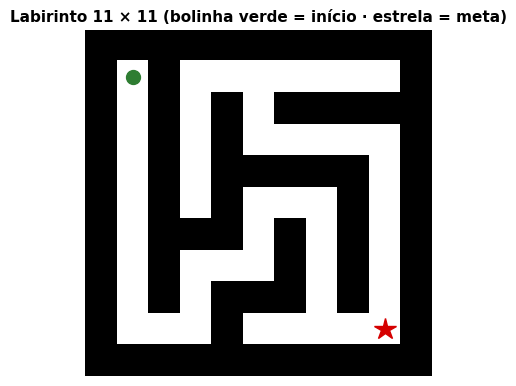

In [3]:
ACOES = [(-1, 0), (1, 0), (0, -1), (0, 1)]          # cima, baixo, esquerda, direita
NOMES = ['Cima', 'Baixo', 'Esquerda', 'Direita']
SETAS = ['↑', '↓', '←', '→']
INICIO = (1, 1)


def gerar_labirinto(size, seed=42):
    '''Sorteia um labirinto size × size (size ímpar) por busca em profundidade. 1 = parede, 0 = livre.'''
    if size % 2 == 0:
        size += 1                                    # o gerador precisa de tamanho ímpar
    np.random.seed(seed)
    random.seed(seed)
    maze = np.ones((size, size), dtype=int)

    def abrir(r, c):
        maze[r, c] = 0
        direcoes = [(0, 2), (0, -2), (2, 0), (-2, 0)]
        random.shuffle(direcoes)
        return iter(direcoes)

    pilha = [((1, 1), abrir(1, 1))]                  # pilha em vez de recursão: funciona em qualquer tamanho
    while pilha:
        (r, c), proximas = pilha[-1]
        for dr, dc in proximas:
            nr, nc = r + dr, c + dc
            if 1 <= nr < size - 1 and 1 <= nc < size - 1 and maze[nr, nc] == 1:
                maze[r + dr // 2, c + dc // 2] = 0   # derruba a parede do meio
                pilha.append(((nr, nc), abrir(nr, nc)))
                break
        else:
            pilha.pop()
    return maze


def meta_de(maze):
    return (maze.shape[0] - 2, maze.shape[1] - 2)


def passo(maze, r, c, a):
    '''O ambiente: anda na direção a (se for parede, fica parado). Devolve (linha, coluna, recompensa).'''
    nr, nc = r + ACOES[a][0], c + ACOES[a][1]
    if maze[nr, nc] == 0:                            # a borda é sempre parede: nunca sai da grade
        r, c = nr, nc
    return r, c, (100 if (r, c) == meta_de(maze) else -1)


# ======================================================================
# 📚 NA AULA · ε-GREEDY: explorar (ação aleatória) × explotar (maior Q)
# ======================================================================
def escolher_acao(Q, r, c, eps):
    if np.random.rand() < eps:
        return np.random.randint(4)                  # explora
    return int(np.argmax(Q[r, c]))                   # explota


# ======================================================================
# 📚 NA AULA · SARSA: Q(s,a) ← Q(s,a) + α · [ r + γ · Q(s',a') − Q(s,a) ]
#   As cinco peças: S = (r, c), A = a, R = recompensa, S' = (r2, c2), A' = a2
# ======================================================================
def atualizar_sarsa(Q, s, a, recompensa, s2, a2, fim, alpha, gamma):
    futuro = 0.0 if fim else Q[s2][a2]               # na meta o episódio acaba: não há futuro
    alvo = recompensa + gamma * futuro
    Q[s][a] += alpha * (alvo - Q[s][a])
    return alvo


def treinar_sarsa(maze, episodios, alpha=0.2, gamma=0.99, eps_inicial=1.0, eps_decay=0.99, eps_min=0.01,
                  max_passos=2000, inicio_aleatorio=False, seed=42, fotos=(), diario=None):
    '''Treina o SARSA e devolve um dicionário com a Q-table, o histórico e as "fotos" da Q-table.'''
    np.random.seed(seed)
    meta = meta_de(maze)
    livres = [(r, c) for r, c in zip(*np.where(maze == 0)) if (r, c) != meta]
    Q = np.zeros(maze.shape + (4,))
    h = {'recompensas': [], 'passos': [], 'sucessos': [], 'epsilons': [], 'fotos': {}}
    eps = eps_inicial
    for ep in range(episodios):
        if ep in fotos:
            h['fotos'][ep] = (Q.copy(), eps)
        r, c = livres[np.random.randint(len(livres))] if inicio_aleatorio else INICIO
        a = escolher_acao(Q, r, c, eps)                                  # A
        total = n = 0
        for _ in range(max_passos):
            r2, c2, recompensa = passo(maze, r, c, a)                    # R e S'
            a2 = escolher_acao(Q, r2, c2, eps)                           # A' (sorteada ANTES de atualizar)
            fim = (r2, c2) == meta
            q_antes = Q[r, c, a]
            alvo = atualizar_sarsa(Q, (r, c), a, recompensa, (r2, c2), a2, fim, alpha, gamma)
            if diario is not None:
                diario.append((ep, (r, c), a, recompensa, (r2, c2), a2, q_antes, alvo, Q[r, c, a]))
            r, c, a = r2, c2, a2                                         # o A' vira o próximo A
            total += recompensa
            n += 1
            if fim:
                break
        h['recompensas'].append(total)
        h['passos'].append(n)
        h['sucessos'].append(int((r, c) == meta))
        h['epsilons'].append(eps)
        eps = max(eps_min, eps * eps_decay)
    h['Q'] = Q
    return h


def caminho_greedy(maze, Q, inicio=INICIO, limite=5000):
    '''Segue a política greedy (ε = 0) a partir de "inicio". Para se chegar à meta ou se repetir uma casa.'''
    r, c = inicio
    caminho, vistos = [(r, c)], {(r, c)}
    for _ in range(limite):
        if (r, c) == meta_de(maze):
            break
        r, c, _ = passo(maze, r, c, int(np.argmax(Q[r, c])))
        caminho.append((r, c))
        if (r, c) in vistos:                         # repetiu: a política entrou em loop
            break
        vistos.add((r, c))
    return caminho


def desenhar(ax, maze, Q=None, caminho=None, setas=False, numeros=False, titulo=''):
    '''Labirinto + (opcional) mapa de calor do maior Q, setas da política e caminho greedy.'''
    meta = meta_de(maze)
    ax.imshow(maze, cmap='binary', origin='upper', zorder=0)
    if Q is not None:
        q = Q.max(axis=2).astype(float)
        nunca = np.all(Q == 0, axis=2)                   # casas nunca atualizadas: sem cor, sem seta
        q[(maze == 1) | nunca] = np.nan
        q[meta] = np.nan
        ax.imshow(q, cmap='YlOrRd', origin='upper', zorder=1)
        livres = [(r, c) for r, c in zip(*np.where(maze == 0)) if (r, c) != meta and not nunca[r, c]]
        if setas:
            melhor = [int(np.argmax(Q[s])) for s in livres]
            ax.quiver([c for _, c in livres], [r for r, _ in livres],
                      [ACOES[a][1] for a in melhor], [ACOES[a][0] for a in melhor],
                      angles='xy', scale_units='xy', scale=1.6, pivot='middle', color='#1565C0',
                      width=0.006 if maze.shape[0] <= 15 else 0.0025, zorder=3)
        if numeros:
            for s in livres:
                ax.text(s[1], s[0] + 0.32, f'{Q[s].max():.0f}', ha='center', va='center', fontsize=6.5, zorder=4)
    if caminho and len(caminho) > 1:
        ax.plot([c for _, c in caminho], [r for r, _ in caminho], color='#1E88E5', lw=3, alpha=0.6, zorder=2)
    ax.plot(INICIO[1], INICIO[0], 'o', color='#2E7D32', ms=10, zorder=5)
    ax.plot(meta[1], meta[0], '*', color='#D50000', ms=16, zorder=5)
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.axis('off')


labirinto_p = gerar_labirinto(11)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
desenhar(ax, labirinto_p, titulo='Labirinto 11 × 11 (bolinha verde = início · estrela = meta)')
plt.show()

### O diário do agente: as primeiras atualizações

Vamos treinar o SARSA por **300 episódios** no labirinto pequeno e ler o "diário" de três momentos:

1. os **primeiros passos** do episódio 0, quando a Q-table ainda é toda zero;
2. a **primeira vez** que ele chega à meta;
3. a **primeira vez** que o +100 "vaza" para uma casa que nem é vizinha da meta.

> 🤔 **Palpite:** no primeiro passo, com tudo zerado, quanto passa a valer o Q? (α = 0,2, γ = 0,99, recompensa −1)

In [4]:
diario = []
treino_p = treinar_sarsa(labirinto_p, episodios=300, diario=diario)
Q_p = treino_p['Q']


def linha(d):
    ep, s, a, rec, s2, a2, q_antes, alvo, q_depois = d
    return (f'ep {ep:>3} | S={str(s):8s} A={NOMES[a]:8s} R={rec:+4d} S\'={str(s2):8s} A\'={NOMES[a2]:8s} | '
            f'alvo = {br(alvo):>6s} | Q: {br(q_antes):>6s} → {br(q_depois):>6s}')


print('1) Os primeiros passos do episódio 0 (Q-table toda zero):')
for d in diario[:5]:
    print('   ' + linha(d))

meta_p = meta_de(labirinto_p)
primeira = next(d for d in diario if d[4] == meta_p)
print(f'\n2) A primeira chegada à meta (episódio {primeira[0]}): o +100 aparece!')
print('   ' + linha(primeira))

vaza = next(d for d in diario if d[4] != meta_p and d[7] > 0)
print(f'\n3) O +100 "vaza para trás" (episódio {vaza[0]}): a casa S′ já vale algo positivo')
print('   ' + linha(vaza))

primeiro_sucesso = treino_p['sucessos'].index(1)
caminho_p = caminho_greedy(labirinto_p, Q_p)
print(f'\nPrimeira chegada à meta: episódio {primeiro_sucesso}. '
      f'Depois do treino, o caminho greedy leva {len(caminho_p) - 1} passos.')

1) Os primeiros passos do episódio 0 (Q-table toda zero):
   ep   0 | S=(1, 1)   A=Cima     R=  -1 S'=(1, 1)   A'=Direita  | alvo =  -1,00 | Q:   0,00 →  -0,20
   ep   0 | S=(1, 1)   A=Direita  R=  -1 S'=(1, 1)   A'=Esquerda | alvo =  -1,00 | Q:   0,00 →  -0,20
   ep   0 | S=(1, 1)   A=Esquerda R=  -1 S'=(1, 1)   A'=Esquerda | alvo =  -1,00 | Q:   0,00 →  -0,20
   ep   0 | S=(1, 1)   A=Esquerda R=  -1 S'=(1, 1)   A'=Direita  | alvo =  -1,20 | Q:  -0,20 →  -0,40
   ep   0 | S=(1, 1)   A=Direita  R=  -1 S'=(1, 1)   A'=Direita  | alvo =  -1,20 | Q:  -0,20 →  -0,40

2) A primeira chegada à meta (episódio 0): o +100 aparece!
   ep   0 | S=(9, 8)   A=Direita  R=+100 S'=(9, 9)   A'=Baixo    | alvo = 100,00 | Q:   0,00 →  20,00

3) O +100 "vaza para trás" (episódio 1): a casa S′ já vale algo positivo
   ep   1 | S=(9, 7)   A=Direita  R=  -1 S'=(9, 8)   A'=Direita  | alvo =  18,80 | Q:  -0,20 →   3,60

Primeira chegada à meta: episódio 0. Depois do treino, o caminho greedy leva 24 passos.


**🔎 O que observar**
- **Primeiros passos:** o início fica num canto, então "Cima" e "Esquerda" batem na parede (S′ = S). Com tudo zerado, o alvo é só a recompensa, −1, e o Q cai para **−0,2** (= 0,2 × −1).
- **Repare no 4º passo:** o alvo já é **−1,20**, e não −1. É que Q(S′, A′) já valia −0,2: o SARSA usou o valor da ação **que vai tomar**. O agente aprende primeiro o que **não** compensa (bater na parede, andar em círculos), e isso o empurra para casas novas, que ainda valem 0.
- **Primeira chegada:** o alvo vira **+100**, e a última casa antes da meta salta para cerca de +20 de uma vez (0,2 × 100).
- **O valor vaza para trás:** num episódio seguinte, uma casa mais distante usa Q(S′, A′) > 0 da vizinha. É o mesmo "vazamento" da cobrinha (slide 104), agora com a ação **que o agente realmente vai tomar**.

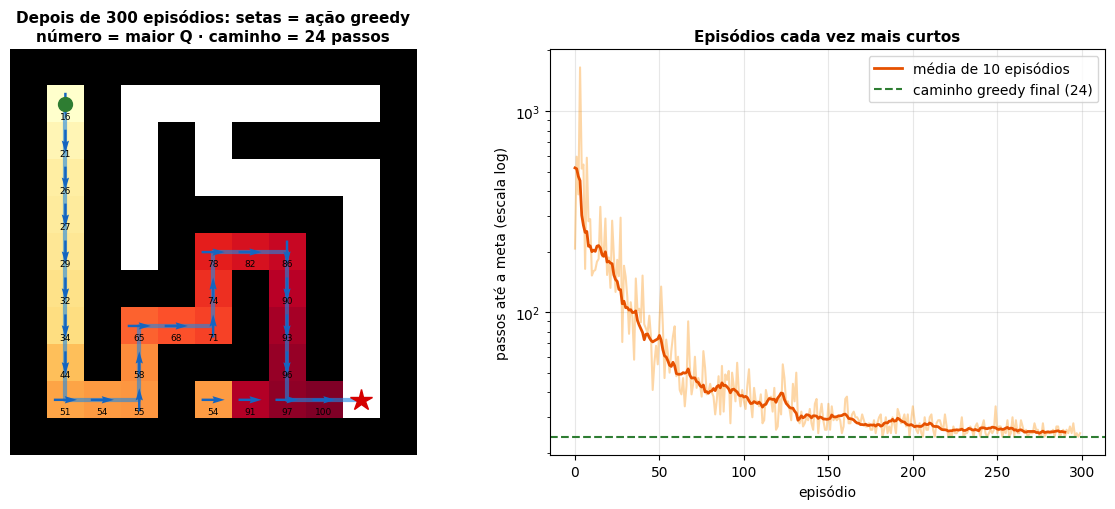

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
desenhar(axes[0], labirinto_p, Q_p, caminho=caminho_p, setas=True, numeros=True,
         titulo=f'Depois de 300 episódios: setas = ação greedy\nnúmero = maior Q · caminho = {len(caminho_p) - 1} passos')
ax = axes[1]
ax.plot(treino_p['passos'], color='#FB8C00', alpha=0.35)
ax.plot(np.convolve(treino_p['passos'], np.ones(10) / 10, mode='valid'), color='#E65100', lw=2, label='média de 10 episódios')
ax.axhline(len(caminho_p) - 1, color='#2E7D32', ls='--', label=f'caminho greedy final ({len(caminho_p) - 1})')
ax.set_yscale('log'); ax.set_xlabel('episódio'); ax.set_ylabel('passos até a meta (escala log)')
ax.set_title('Episódios cada vez mais curtos', fontsize=11, fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**🔎 O que observar**
- **O mapa de calor** (amarelo → vermelho) mostra o maior Q de cada casa: quanto mais perto da meta, mais quente. É o +100 que vazou para trás, descontado de −1 a cada passo.
- **As setas** formam um "rio" que desce até a meta. Casas **brancas, sem seta nem número**, nunca foram visitadas. Neste labirinto, a região branca só é alcançável **passando pela meta**, e o episódio acaba assim que o agente chega lá!
- **No gráfico,** os primeiros episódios levam centenas de passos; no fim, o agente faz o caminho quase direto.

---
## 3. 🎯 Mão na massa 1 — Assista ao agente no labirinto 51 × 51 (slide 110)

Agora, o desafio de verdade: um labirinto **51 × 51**, com **10.000 episódios** de treino (α = 0,2, γ = 0,99, ε caindo de 1 até 0,01). Guardamos "fotos" da Q-table nos episódios 0 e 100.

> ⏱️ Esta célula leva cerca de **30 a 60 segundos**.

In [6]:
SIZE = 51   # 👈 experimente 31 (mais rápido) ou 71 (bem mais difícil)
labirinto = gerar_labirinto(SIZE)
SIZE = labirinto.shape[0]
EPISODIOS = 10_000

inicio_t = time.time()
treino = treinar_sarsa(labirinto, EPISODIOS, fotos=(0, 100))
Q = treino['Q']
caminho = caminho_greedy(labirinto, Q)
chegou = caminho[-1] == meta_de(labirinto)

print(f'Labirinto {SIZE} × {SIZE}: {int((labirinto == 0).sum())} casas livres.')
print(f'Treino de {EPISODIOS:,} episódios em {time.time() - inicio_t:.0f} s.'.replace(',', '.'))
print(f'Primeira chegada à meta: episódio {treino["sucessos"].index(1)}.')
print(f'Sucesso nos últimos 200 episódios: {np.mean(treino["sucessos"][-200:]):.0%}.')
print(f'Política greedy a partir do início: {"chega à meta" if chegou else "NÃO chega"} em {len(caminho) - 1} passos.')

Labirinto 51 × 51: 1249 casas livres.
Treino de 10.000 episódios em 41 s.
Primeira chegada à meta: episódio 1474.
Sucesso nos últimos 200 episódios: 100%.
Política greedy a partir do início: chega à meta em 528 passos.


> 🤔 **Palpite (slide 110):** no **episódio 0**, o agente anda ao acaso por até 2.000 passos. Ele chega a sair de perto do início? E no **episódio 100**, com ε ≈ 0,37?

Cada painel abaixo mostra **um episódio** jogado com a Q-table e o ε daquele momento do treino. Episódios longos são acelerados (a animação pula passos), mas o contador mostra o passo real.

In [7]:
# @title ▶️ Funções de animação (pode só rodar)
def rodar_episodio(maze, Q, eps, seed=0, max_passos=2000):
    '''Um episódio com ε-greedy usando a Q-table dada. Não altera a Q-table.'''
    rng = np.random.default_rng(seed)
    r, c = INICIO
    total, traj = 0, [((r, c), 0)]
    for _ in range(max_passos):
        a = int(rng.integers(4)) if rng.random() < eps else int(np.argmax(Q[r, c]))
        r, c, rec = passo(maze, r, c, a)
        total += rec
        traj.append(((r, c), total))
        if (r, c) == meta_de(maze):
            break
    return traj


def animar(maze, trajetorias, titulos, max_quadros=50):
    n = len(trajetorias)
    fig, axes = plt.subplots(1, n, figsize=(4.6 * n, 5.4), dpi=60)
    pulo = [max(1, -(-len(t) // max_quadros)) for t in trajetorias]
    n_quadros = max(-(-len(t) // p) for t, p in zip(trajetorias, pulo)) + 6      # +6: pausa no fim
    paineis = []
    for ax, traj, tit in zip(axes, trajetorias, titulos):
        desenhar(ax, maze)
        rastro, = ax.plot([], [], '-', color='#1565C0', alpha=0.4, lw=3, zorder=6)
        ponto, = ax.plot([], [], 'o', color='#1565C0', ms=12, mec='white', mew=2, zorder=8)
        paineis.append((traj, rastro, ponto, ax, tit))
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.02, top=0.84, wspace=0.08)

    def quadro(k):
        for (traj, rastro, ponto, ax, tit), p in zip(paineis, pulo):
            i = min(k * p, len(traj) - 1)
            ys, xs = zip(*[e for e, _ in traj[:i + 1]])
            rastro.set_data(xs, ys)
            ponto.set_data([xs[-1]], [ys[-1]])
            fim = 'em andamento…'
            if i == len(traj) - 1:
                fim = '★ chegou!' if traj[i][0] == meta_de(maze) else 'não chegou (limite de 2.000 passos)'
            ax.set_title(f'{tit}\npasso {i} | recompensa {traj[i][1]:+d}\n{fim}', fontsize=11, fontweight='bold')
        return []

    anim = animation.FuncAnimation(fig, quadro, frames=n_quadros, interval=180)
    plt.close(fig)
    return HTML(anim.to_jshtml(default_mode='once'))

In [8]:
trajetorias, titulos = [], []
for ep, (Q_ep, eps_ep) in treino['fotos'].items():
    trajetorias.append(rodar_episodio(labirinto, Q_ep, eps_ep, seed=1))
    titulos.append(f'Episódio {ep} (ε = {br(eps_ep)})')
trajetorias.append(rodar_episodio(labirinto, Q, 0.0))
titulos.append(f'Depois de {EPISODIOS:,} episódios (ε = 0)'.replace(',', '.'))
animar(labirinto, trajetorias, titulos)

**🔎 O que observar**
- **Episódio 0:** andando ao acaso, o agente fica **preso perto do início** e esgota os 2.000 passos sem ver a meta.
- **Episódio 100:** a Q-table já empurra o agente para casas novas (as visitadas ficaram negativas), mas ε ≈ 0,37 ainda o faz tropeçar bastante.
- **Depois do treino:** o caminho é direto, sem hesitar.

**Para pensar**
1. Num labirinto **grande**, por que andar ao acaso é um problema sério? Pense em quantos episódios passam até o +100 aparecer pela primeira vez.
2. Até a primeira chegada à meta, toda recompensa é −1. O que o agente aprende nesse período? (Dica: Q começa em 0 e só desce onde ele passou. O que isso faz com a escolha greedy?)

### Os quatro termômetros do treino

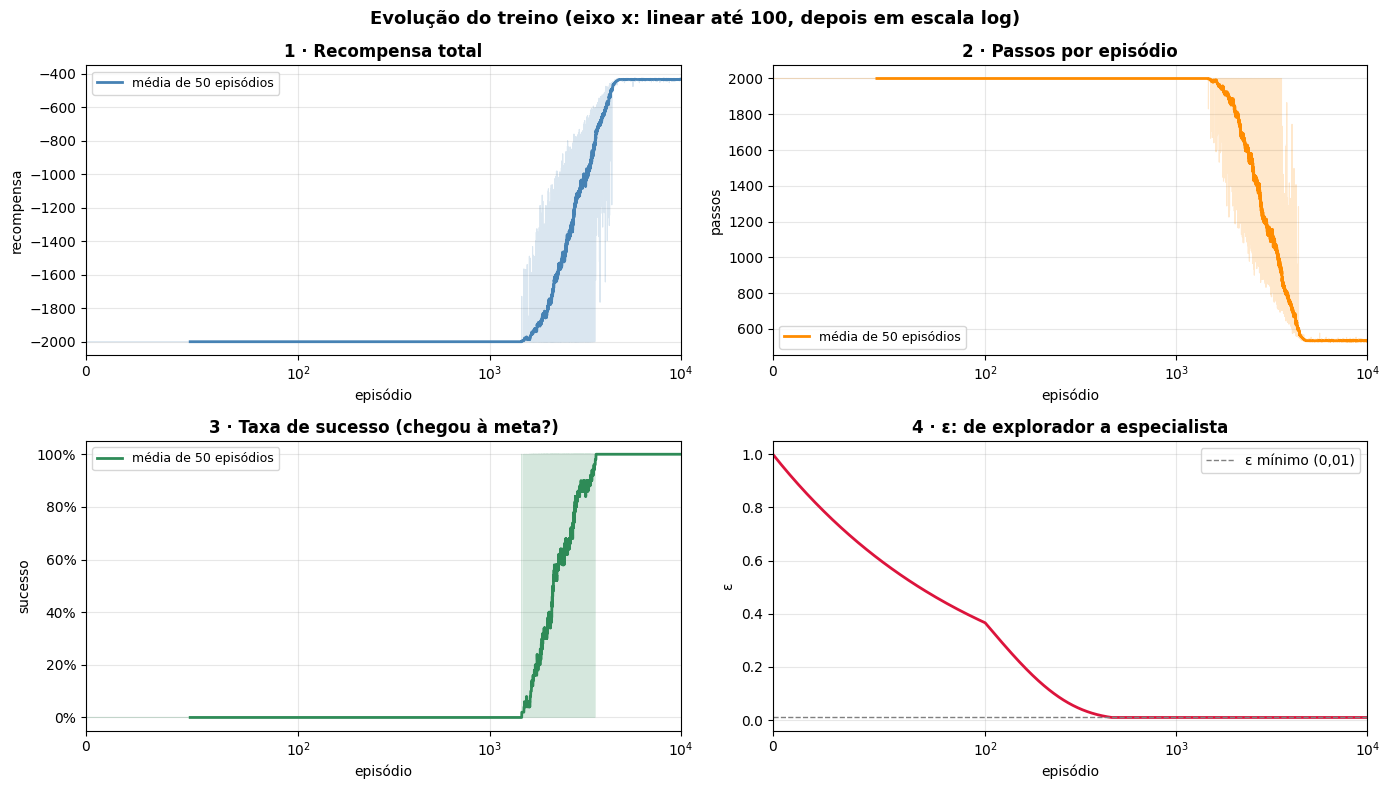

In [9]:
def serie(ax, dados, cor, titulo, ylabel, janela=50, pct=False):
    ax.plot(dados, alpha=0.2, color=cor, lw=0.8)
    ax.plot(range(janela - 1, len(dados)), np.convolve(dados, np.ones(janela) / janela, mode='valid'),
            color=cor, lw=2, label=f'média de {janela} episódios')
    if pct:
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax.set_title(titulo, fontsize=12, fontweight='bold'); ax.set_xlabel('episódio'); ax.set_ylabel(ylabel)
    ax.legend(fontsize=9); ax.grid(alpha=0.3)


fig, axes = plt.subplots(2, 2, figsize=(14, 8))
serie(axes[0, 0], treino['recompensas'], 'steelblue', '1 · Recompensa total', 'recompensa')
serie(axes[0, 1], treino['passos'], 'darkorange', '2 · Passos por episódio', 'passos')
serie(axes[1, 0], treino['sucessos'], 'seagreen', '3 · Taxa de sucesso (chegou à meta?)', 'sucesso', pct=True)
axes[1, 1].plot(treino['epsilons'], color='crimson', lw=2)
axes[1, 1].axhline(0.01, color='gray', ls='--', lw=1, label='ε mínimo (0,01)')
axes[1, 1].set_title('4 · ε: de explorador a especialista', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('episódio'); axes[1, 1].set_ylabel('ε'); axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)
for ax in axes[:, 0].tolist() + [axes[0, 1], axes[1, 1]]:
    ax.set_xscale('symlog', linthresh=100)
    ax.set_xlim(0, EPISODIOS)
fig.suptitle('Evolução do treino (eixo x: linear até 100, depois em escala log)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**🔎 O que observar:** quase tudo acontece nas **primeiras centenas de episódios**, enquanto o ε cai. Por isso o eixo x está em escala log depois do episódio 100: sem isso, o trecho interessante ficaria espremido no canto esquerdo. Depois que o ε chega a 0,01, as curvas ficam quase planas: o agente já achou o caminho e só o repete.

---
## 4. 🎯 Mão na massa 2 — Leia a política (slide 110)

A **política greedy** é: em cada casa, siga a seta da ação de maior Q.

> 🤔 **Palpite:** a partir do início ela chega à meta. E a partir de uma casa **qualquer** do labirinto? Em quantos % das casas livres você acha que a política funciona?

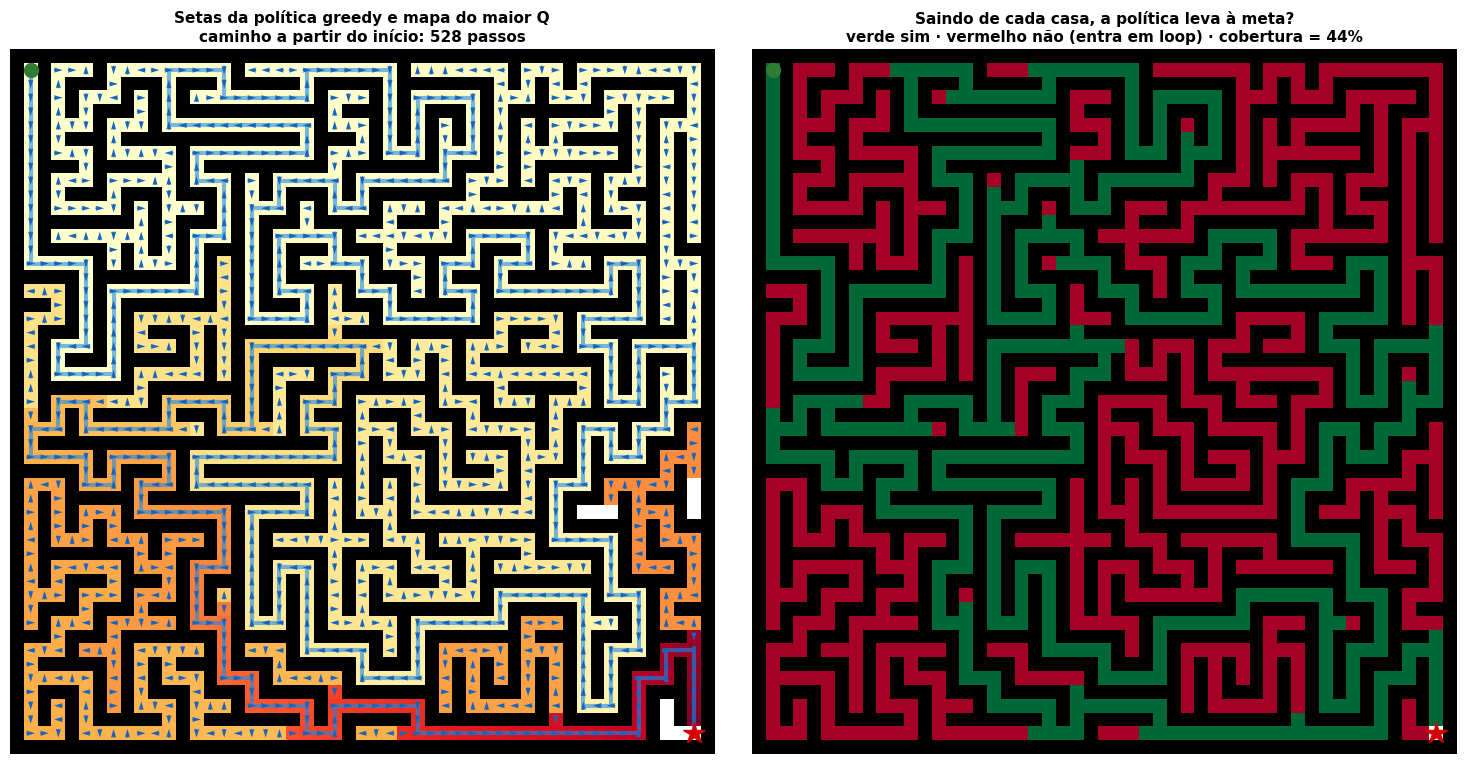

A política greedy leva à meta a partir de 552 de 1248 casas livres (44%).
Mas o agente passou por 99% das casas pelo menos uma vez durante o treino.


In [10]:
meta = meta_de(labirinto)
livres = [(r, c) for r, c in zip(*np.where(labirinto == 0)) if (r, c) != meta]
funciona = {s: caminho_greedy(labirinto, Q, inicio=s)[-1] == meta for s in livres}
cobertura = np.mean(list(funciona.values()))

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
desenhar(axes[0], labirinto, Q, caminho=caminho, setas=True,
         titulo=f'Setas da política greedy e mapa do maior Q\ncaminho a partir do início: {len(caminho) - 1} passos')
mapa = np.full(labirinto.shape, np.nan)
for s, ok in funciona.items():
    mapa[s] = 1.0 if ok else 0.0
axes[1].imshow(labirinto, cmap='binary', origin='upper')
axes[1].imshow(mapa, cmap='RdYlGn', vmin=0, vmax=1, origin='upper')
axes[1].plot(INICIO[1], INICIO[0], 'o', color='#2E7D32', ms=10); axes[1].plot(meta[1], meta[0], '*', color='#D50000', ms=16)
axes[1].set_title(f'Saindo de cada casa, a política leva à meta?\n🟩 sim · 🟥 não (entra em loop) · cobertura = {cobertura:.0%}'
                  .replace('🟩', 'verde').replace('🟥', 'vermelho'), fontsize=11, fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()

visitadas = np.mean([np.any(Q[s] != 0) for s in livres])
print(f'A política greedy leva à meta a partir de {sum(funciona.values())} de {len(livres)} casas livres ({cobertura:.0%}).')
print(f'Mas o agente passou por {visitadas:.0%} das casas pelo menos uma vez durante o treino.')

**🔎 O que observar**
- **O verde segue o caminho principal** entre o início e a meta, e as ruas que desembocam nele. O vermelho fica nos **becos laterais**, longe da rota.
- **Quase tudo foi visitado,** mas a cobertura fica bem abaixo disso. Visitado **uma vez** não é o mesmo que visitado **o suficiente**: um beco que o agente explorou duas vezes no começo do treino ainda tem setas que apontam umas para as outras (loop).
- **SARSA é on-policy:** ele aprende bem **onde ele anda**. Como ele sempre sai do mesmo início e, com ε baixo, repete o mesmo caminho, o resto do labirinto fica "desatualizado".

### Leia a Q-table de uma casa

In [11]:
vizinha_meta = caminho[-2] if chegou else caminho[-1]
casas = [('Início', INICIO), ('Meio do caminho', caminho[len(caminho) // 2]), ('Vizinha da meta', vizinha_meta)]
print(f"{'Casa':24s}" + ''.join(f'{n:>10s}' for n in NOMES) + '   → escolhe')
for nome, s in casas:
    q = Q[s]
    print(f'{nome + " " + str(s):24s}' + ''.join(f'{br(v, 1):>10s}' for v in q) + f'   → {SETAS[int(np.argmax(q))]} {NOMES[int(np.argmax(q))]}')
print('\n(A própria meta não aparece: o episódio acaba ao chegar lá, então a Q-table da meta nunca é atualizada.)')

Casa                          Cima     Baixo  Esquerda   Direita   → escolhe
Início (1, 1)                -99,4     -99,3     -99,4     -99,4   → ↓ Baixo
Meio do caminho (29, 41)     -89,6     -87,6     -88,6     -88,4   → ↓ Baixo
Vizinha da meta (48, 49)      94,3     100,0      97,5      94,6   → ↓ Baixo

(A própria meta não aparece: o episódio acaba ao chegar lá, então a Q-table da meta nunca é atualizada.)


**🔎 O que observar**
- **Perto da meta:** a vizinha tem Q = 100 na ação certa. As outras ações valem menos, porque gastam passos (−1 cada) antes de chegar lá.
- **Longe da meta, todo Q é negativo** (≈ −99 no início). São mais de 500 passos de −1 até a meta, e o +100, descontado por 0,99 a cada passo, chega lá quase apagado (0,99⁵²⁸ ≈ 0,005).
- **E mesmo assim o agente acerta:** a política não precisa de valores positivos, só de saber qual ação é **a menos ruim**. No início, a diferença entre as ações é pequena, mas é ela que aponta o caminho.

---
## 5. A pergunta da turma (slide 110): como fazer o SARSA aprender o labirinto **inteiro**?

> 🤔 **Palpite:** discutam em dupla antes de abrir a dica.

<details>
<summary><b>Dica</b></summary>

O agente aprende bem só onde ele anda. E ele sempre começa no mesmo lugar...
</details>

**Uma resposta:** começar cada episódio numa **casa sorteada** do labirinto (em inglês, *exploring starts*). Assim todas as regiões recebem visitas desde o começo, não só a rota principal.

Para ficar rápido, o teste é num labirinto **21 × 21**, com 3.000 episódios para cada jeito de treinar.

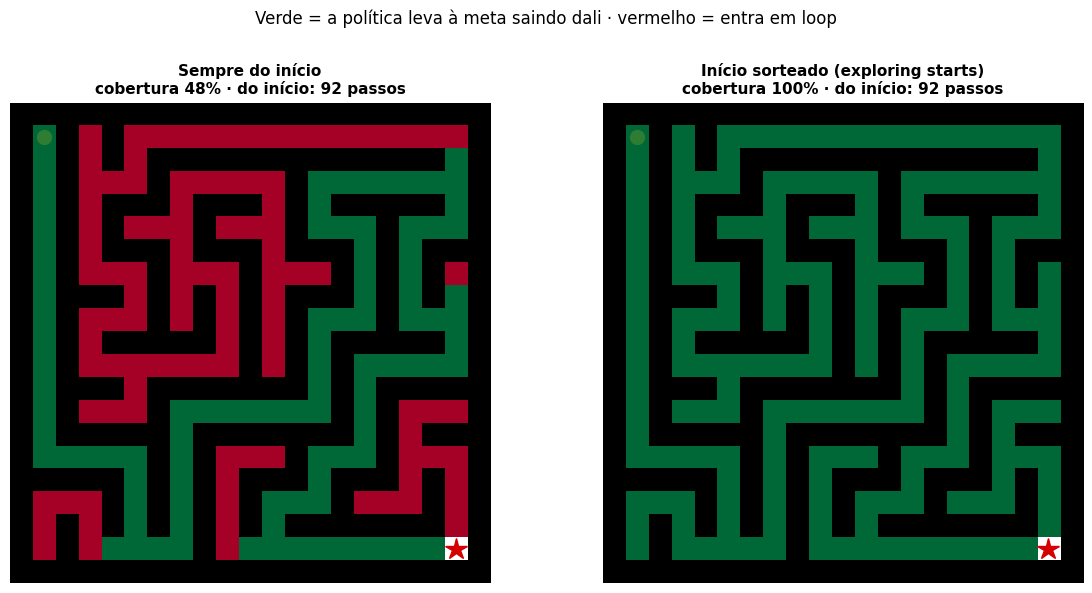

In [12]:
labirinto_m = gerar_labirinto(21)
meta_m = meta_de(labirinto_m)
livres_m = [(r, c) for r, c in zip(*np.where(labirinto_m == 0)) if (r, c) != meta_m]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, aleatorio, nome in [(axes[0], False, 'Sempre do início'), (axes[1], True, 'Início sorteado (exploring starts)')]:
    Q_m = treinar_sarsa(labirinto_m, 3000, inicio_aleatorio=aleatorio)['Q']   # 👈 inicio_aleatorio
    ok = {s: caminho_greedy(labirinto_m, Q_m, inicio=s)[-1] == meta_m for s in livres_m}
    mapa = np.full(labirinto_m.shape, np.nan)
    for s, v in ok.items():
        mapa[s] = float(v)
    ax.imshow(labirinto_m, cmap='binary', origin='upper')
    ax.imshow(mapa, cmap='RdYlGn', vmin=0, vmax=1, origin='upper')
    ax.plot(INICIO[1], INICIO[0], 'o', color='#2E7D32', ms=10); ax.plot(meta_m[1], meta_m[0], '*', color='#D50000', ms=16)
    passos_inicio = len(caminho_greedy(labirinto_m, Q_m)) - 1
    ax.set_title(f'{nome}\ncobertura {np.mean(list(ok.values())):.0%} · do início: {passos_inicio} passos',
                 fontsize=11, fontweight='bold')
    ax.axis('off')
fig.suptitle('Verde = a política leva à meta saindo dali · vermelho = entra em loop', fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

**🔎 O que observar:** com o mesmo número de episódios, o início sorteado cobre o labirinto **inteiro**, e o caminho a partir do início continua o mesmo. O preço: no mundo real, nem sempre dá para "teletransportar" o agente para qualquer lugar. Por isso também existem outras saídas, como mais exploração (ε maior por mais tempo) ou mais episódios.

---
## 6. 🎯 Mão na massa 3 — Mexa nos hiperparâmetros (slides 110 e 106)

Rodamos o SARSA várias vezes, mudando **um hiperparâmetro por vez**:

| Hiperparâmetro | O que controla |
|---|---|
| α | a velocidade de atualização dos Q-values |
| γ | o peso das recompensas futuras × imediatas |
| decaimento do ε | a velocidade da troca exploração → explotação |
| ε fixo | explorar sempre na mesma dose |

Usamos o labirinto **21 × 21** com 500 episódios: no 51 × 51, com tão poucos episódios, o agente quase nunca chega à meta e todas as curvas ficariam iguais. Cada configuração roda com **2 sementes**, e mostramos a média (slide 138: um único treino não prova nada).

> 🤔 **Palpite:** qual dos três mexe mais no aprendizado: α, γ ou ε?
>
> ⏱️ Esta célula leva uns 20 segundos.

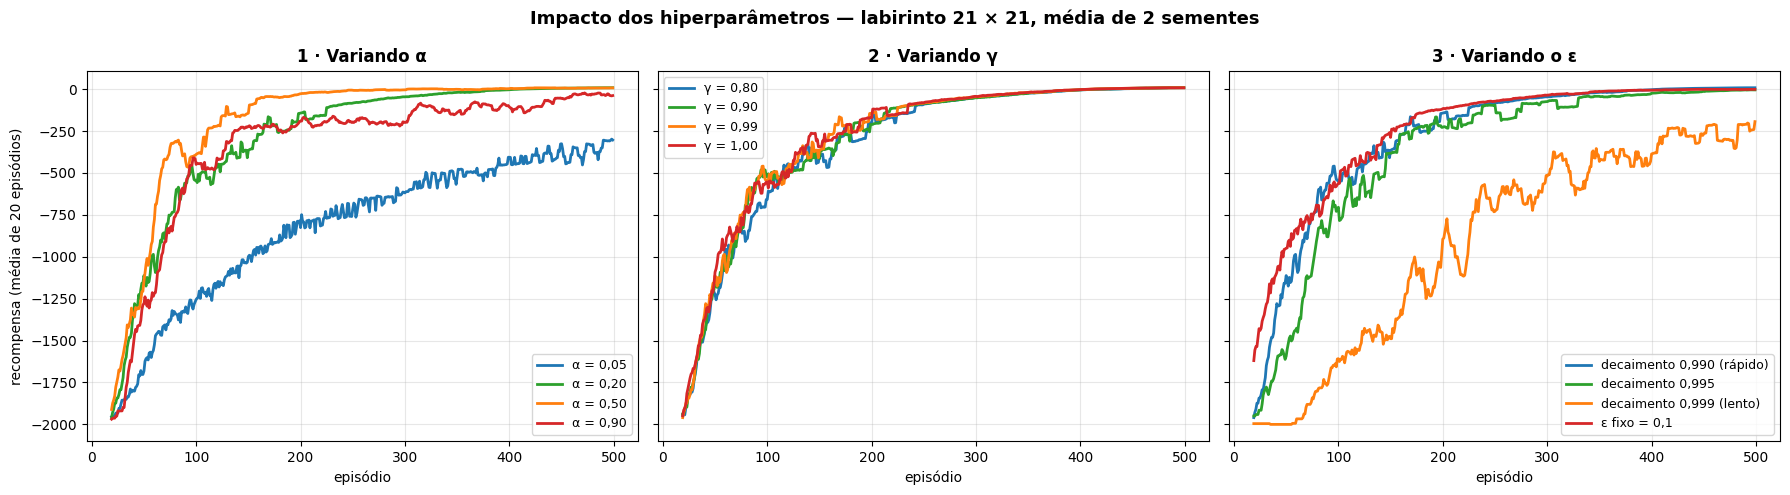

Configuração                sucesso  recompensa no 1º quarto  nos últimos 100
α = 0,05                        76%                    -1503             -370
α = 0,20                        90%                     -993                5
α = 0,50                        93%                     -806                6
α = 0,90                        91%                    -1038              -64
γ = 0,80                        90%                    -1046                4
γ = 0,90                        90%                    -1010                5
γ = 0,99                        90%                     -993                5
γ = 1,00                        91%                     -986                5
decaimento 0,990 (rápido)       90%                     -993                5
decaimento 0,995                87%                    -1189              -13
decaimento 0,999 (lento)        68%                    -1808             -255
ε fixo = 0,1                    95%                     -862    

In [13]:
EPS, JANELA, SEMENTES = 500, 20, [0, 1]
cores = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']
experimentos = [
    ('1 · Variando α', [(f'α = {br(v)}', dict(alpha=v)) for v in [0.05, 0.2, 0.5, 0.9]]),
    ('2 · Variando γ', [(f'γ = {br(v)}', dict(gamma=v)) for v in [0.80, 0.90, 0.99, 1.00]]),
    ('3 · Variando o ε', [('decaimento 0,990 (rápido)', dict(eps_decay=0.990)),
                          ('decaimento 0,995', dict(eps_decay=0.995)),
                          ('decaimento 0,999 (lento)', dict(eps_decay=0.999)),
                          ('ε fixo = 0,1', dict(eps_inicial=0.1, eps_decay=1.0))]),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
tabela = []
for ax, (titulo, configs) in zip(axes, experimentos):
    for (rotulo, kw), cor in zip(configs, cores):
        execucoes = [treinar_sarsa(labirinto_m, EPS, seed=s, **kw) for s in SEMENTES]
        recs = np.mean([e['recompensas'] for e in execucoes], axis=0)
        sucs = np.mean([e['sucessos'] for e in execucoes], axis=0)
        ax.plot(range(JANELA - 1, EPS), np.convolve(recs, np.ones(JANELA) / JANELA, mode='valid'), color=cor, lw=2, label=rotulo)
        tabela.append((rotulo, sucs.mean(), recs[:EPS // 4].mean(), recs[-100:].mean()))
    ax.set_title(titulo, fontsize=12, fontweight='bold'); ax.set_xlabel('episódio'); ax.legend(fontsize=9); ax.grid(alpha=0.3)
axes[0].set_ylabel(f'recompensa (média de {JANELA} episódios)')
fig.suptitle('Impacto dos hiperparâmetros — labirinto 21 × 21, média de 2 sementes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"{'Configuração':26s} {'sucesso':>8s} {'recompensa no 1º quarto':>24s} {'nos últimos 100':>16s}")
for rotulo, suc, ini, fim in tabela:
    print(f'{rotulo:26s} {suc:8.0%} {br(ini, 0):>24s} {br(fim, 0):>16s}')

**🔎 O que observar (neste labirinto, com estas sementes)**
- **α:** muito baixo (0,05) aprende devagar: em 500 episódios ainda não estabilizou. Entre 0,2 e 0,5 está o melhor equilíbrio aqui. Muito alto (0,9) não acelera e oscila mais.
- **γ entre 0,8 e 1,0:** praticamente o mesmo resultado. A penalidade de −1 por passo já premia o caminho curto, mesmo quando o γ "apaga" o +100 distante.
- **Decaimento lento do ε (0,999):** gasta os 500 episódios explorando (ε ainda ≈ 0,6 no fim) e é o que mais atrapalha.
- **ε fixo = 0,1:** chega à meta mais vezes e aprende rápido no começo, mas nunca para de explorar, então nos últimos episódios rende um pouco menos que o ε caindo até 0,01.
- **Resposta do palpite:** neste labirinto, o **ε** (quanto e por quanto tempo explorar) e os extremos de **α** mexem muito mais que o γ.

> Resultados de RL variam com a semente. Troque `SEMENTES` e veja quanto as curvas mudam antes de tirar conclusões.

---
## 🏁 Resumo: o que o SARSA ensinou

| Ideia | Onde você viu |
|---|---|
| As cinco peças S, A, R, S′, A′ | o diário do agente (seção 2) |
| O alvo usa a ação **que vai ser tomada**, não a melhor | a conta do slide 109 (seção 1) |
| Com ε = 0, SARSA e Q-Learning coincidem | a pergunta da seção 1 |
| O valor vaza para trás a partir da meta | o mapa de calor (seções 2 e 4) |
| On-policy: aprende bem **onde anda** | a cobertura da política (seção 4) |
| Sair de casas sorteadas cobre o labirinto inteiro | a pergunta da turma (seção 5) |

## 💭 Para pensar (em dupla)

1. **On-policy no mundo real:** um robô de armazém que explora com ε = 0,1 pode bater em prateleiras enquanto aprende. Por que, nesse caso, aprender o valor **com** as próprias explorações (SARSA) pode ser mais seguro que supor jogadas perfeitas (Q-Learning)?
2. **Caminho mais curto?** O caminho greedy no 51 × 51 é o mais curto possível? Como você verificaria? (Dica: uma busca em largura no labirinto dá a resposta exata.)
3. **Recompensa:** o que aconteceria se bater na parede custasse −5 em vez de −1?

**Próximo passo:** no **penhasco** (slides 111 a 114), Q-Learning e SARSA aprendem caminhos **diferentes** no mesmo mundo. Veja em `exercicio_qlearning_sarsa.ipynb`.